# Lesson 1: From decision to evidence

<p class="lead">
Turn a vague business request into a clear question, load a real retail dataset, and build a first chart you can explain.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/01_decision_to_evidence.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The head of a retail business says:

> *"Sales feel uneven across our customer groups. I need to know where to look first."*

This is not yet a question you can answer with data. Today you turn it into one, and take a first look at the evidence.

> **About the data**
>
> We use the **Superstore** sample published by Tableau. It describes a **fictitious** company, not a real one. Sales and Profit are in the file's own monetary units; the currency is not stated, so we never label it as dollars, rupees or anything else.

---

## What you will be able to do

1. Write a business question that names a decision, a population and a period.
2. Load the course data and check its size and column types.
3. Explain the difference between **one row** and **one order**.
4. Build a simple bar chart and filter the data.

**Evidence you keep:** your written question, your first chart and a one-sentence explanation of what a row means.

Before you start, read the [Foundations](../foundations/index.md) pages and complete [Lesson 0](00_python_and_colab_basics.md).

---

## Part 1: From request to question

A good analytical question answers four things:

| Part | Ask yourself | Example |
|---|---|---|
| **Decision** | What will someone do differently? | Choose one customer segment to investigate next month |
| **Population** | Which records count? | All order lines in the course data |
| **Period** | Which dates? | Orders placed in 2023, 2024 and 2025 |
| **Measure** | What will we compare? | Sales by customer segment |

> *"Which customer segment had the highest Sales for orders placed in 2023–2025, so we can choose one segment to investigate next month?"*

> **Your turn**
>
> Rewrite the head's request as your own one-sentence question, using the four parts.

---

## Part 2: Load the data

Run the setup cell first. It downloads the sample from Tableau's website, checks it is exactly the version this course was written for, and prepares the table. You will learn what each step does in Lesson 2.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


Now load the table into a variable called `df` and look at the first rows.

In [2]:
df = load_orders()
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,segment,country_region,region,category,...,product_name,sales,quantity,discount,profit,returned_order_flag,customer_analysis_eligible,customer_order_conflict,order_to_ship_days,order_month
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Consumer,United States,Central,Office Supplies,...,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.20,5.55,0,1,0,4,2023-01-01
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Home Office,United States,Central,Office Supplies,...,GBC Standard Plastic Binding Systems Combs,3.54,2,0.80,-5.49,0,1,0,4,2023-01-01
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Home Office,United States,Central,Office Supplies,...,Avery 508,11.78,3,0.20,4.27,0,1,0,4,2023-01-01
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Home Office,United States,Central,Office Supplies,...,SAFCO Boltless Steel Shelving,272.74,3,0.20,-64.77,0,1,0,4,2023-01-01
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Consumer,United States,East,Office Supplies,...,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,0.20,4.88,0,1,0,7,2023-01-01


### How big is it, and what types are the columns?

In [3]:
print("Rows, columns:", df.shape)
df.dtypes

Rows, columns: (6815, 22)


row_id                                 int64
order_id                              object
order_date                    datetime64[ns]
ship_date                     datetime64[ns]
ship_mode                             object
customer_id                           object
segment                               object
country_region                        object
region                                object
category                              object
sub_category                          object
product_id                            object
product_name                          object
sales                                float64
quantity                               int64
discount                             float64
profit                               float64
returned_order_flag                    int64
customer_analysis_eligible             int64
customer_order_conflict                int64
order_to_ship_days                     int64
order_month                   datetime64[ns]
dtype: obj

Check the types make sense:

- `order_id`, `segment`, `region` are text (`object`).
- `sales`, `profit`, `discount` are decimals (`float64`); `quantity` is a whole number.
- `order_date`, `ship_date`, `order_month` are dates (`datetime64`).

> **IDs are not amounts**
>
> `row_id` is stored as a number, but adding it up means nothing. It is an identifier.

### Which dates are included?

In [4]:
print("First order date:", df["order_date"].min().date())
print("Last order date: ", df["order_date"].max().date())

First order date: 2023-01-03
Last order date:  2025-12-31


---

## Part 3: Rows versus orders

Look at the rows that share one `order_id`:

In [5]:
df[df["order_id"] == "US-2023-112326"][["order_id", "order_date", "segment", "product_name", "sales"]]

,order_id,order_date,segment,product_name,sales
1,US-2023-112326,2023-01-04,Home Office,GBC Standard Plastic Binding Systems Combs,3.54
2,US-2023-112326,2023-01-04,Home Office,Avery 508,11.78
3,US-2023-112326,2023-01-04,Home Office,SAFCO Boltless Steel Shelving,272.74


One order, several rows. Each row is one **order line**: one product within an order. So the number of rows is **not** the number of orders.

In [6]:
print("Rows (order lines):", len(df))
print("Different orders:  ", df["order_id"].nunique())

Rows (order lines): 6815
Different orders:   3388


> **Remember**
>
> `len(df)` counts **rows**. `df["order_id"].nunique()` counts **different orders**. You will use the second one whenever a question is about orders.

---

## Part 4: A first chart

Total Sales for each customer segment:

In [7]:
sales_by_segment = df.groupby("segment")["sales"].sum().sort_values()
sales_by_segment

segment
Home Office   277,656.95
Corporate     467,562.02
Consumer      835,747.86
Name: sales, dtype: float64

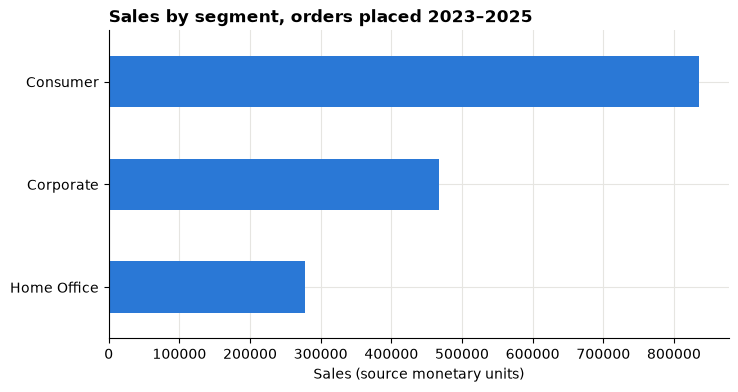

In [8]:
sales_by_segment.plot(kind="barh", title="Sales by segment, orders placed 2023–2025")
plt.xlabel("Sales (source monetary units)")
plt.ylabel("")
plt.show()

### Add a filter

The same chart for one region only. The filter keeps rows where `region` is `"West"`.

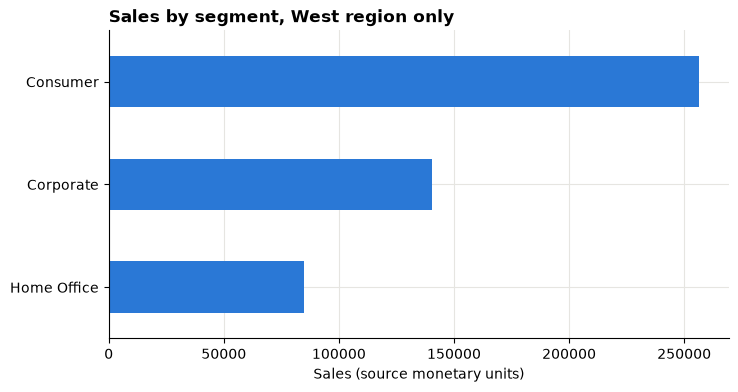

In [9]:
west = df[df["region"] == "West"]
west.groupby("segment")["sales"].sum().sort_values().plot(
    kind="barh", title="Sales by segment, West region only"
)
plt.xlabel("Sales (source monetary units)")
plt.ylabel("")
plt.show()

> **Write it down**
>
> Every time you filter, record it in your evidence log. A chart without its filters written down is easy to misread later.

---

## Part 5: Your turn

> **Your turn:** change the code in the next cell and run it again.

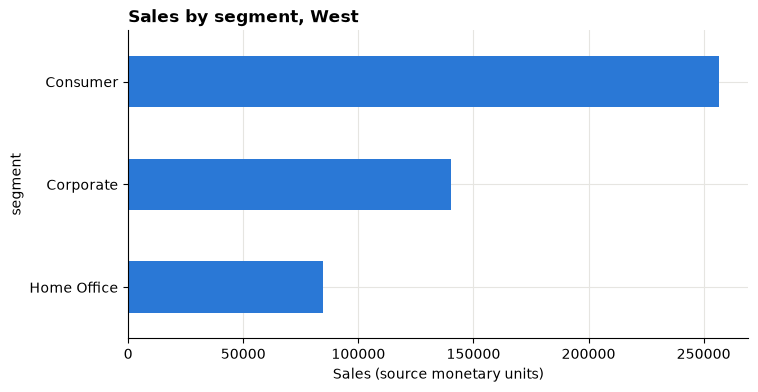

In [10]:
# 1. Change "segment" to "category" to see Sales by product category.
# 2. Change "West" to another region: "East", "Central" or "South".
# 3. Update the title so it says exactly what the chart shows.
selected = df[df["region"] == "West"]
selected.groupby("segment")["sales"].sum().sort_values().plot(kind="barh", title="Sales by segment, West")
plt.xlabel("Sales (source monetary units)")
plt.show()

Write one sentence describing what your chart shows. Do not explain *why* yet.

---

## Part 6: Challenge

A colleague says:

> *"The biggest bar is the best segment, so we should invest there."*

In two or three sentences, explain why a bigger Sales bar alone does not tell us where to invest. What else would you want to see?

---

## Exit ticket

1. Your one-sentence business question.
2. What one row of `df` represents.
3. One thing you are still unsure about.

## After the lesson

- Start your **evidence log**: today's question, the data version and any filters you used.
- Read the [Analytical workflow](../course/workflow.md) page.
- Next: [Lesson 2](02_trust_the_sales_table.md), checking whether the sales table can be trusted.